<font size=10>**PREQUENTIAL EVALUATION**</font> <a class="anchor" id='title'></a>

**Master's in Data Science & Advanced Analytics - NOVA IMS (26/27)**

**Course**: *Data Stream Mining — Practical Assignment I (PA48)*

**Project**: *Weather Windows for Outdoor Races — Angra do Heroísmo vs Braga*

**Group PA48**
- Beatriz Marques 20231605
- Duarte Fernandes 20231619

**Question**: *Which city offers more reliable weather windows for recurring outdoor races?*

**Pipeline step**: This notebook reproduces **step 3 and saving** of `python src/practical_assignment.py --config config.yaml`: rebuild the streams, run warm-up and test-then-train evaluation for every city, representation and learner, and write the three audit outputs. The single-run examples are separate demonstrations with fresh models.

| Notebook | What it does |
|---|---|
| 01 — `01_data_collection_and_quality.ipynb` | Data collection and quality |
| 02 — `02_target_and_features.ipynb` | Target, features and shared mask |
| **03 — `03_prequential_evaluation.ipynb`** | **Evaluation and audit outputs** |
| 04 — `04_results_and_figures.ipynb` | Results, figures and audit checks |

<font color='#BFD72F' size=6>**TABLE OF CONTENTS**</font> <a class="anchor" id='toc'></a>

- [1. Imports](#1)

- [2. Experiment Setup](#2)
    - [2.1 Configuration & Seed](#2_1)
    - [2.2 Streams](#2_2)

- [3. Inside One Run](#3)
    - [3.1 Predict → Evaluate → Learn by Hand](#3_1)
    - [3.2 One Full Run with run_prequential](#3_2)
    - [3.3 Model Complexity](#3_3)
    - [3.4 Cumulative vs Window Macro-F1](#3_4)
        - [Insights](#insights_1)

- [4. Full Experiment](#4)
    - [4.1 Run All Cities × Representations × Models](#4_1)
    - [4.2 Save Audit Outputs](#4_2)
    - [4.3 Quick Look](#4_3)
        - [Insights](#insights_2)

# <font color='#BFD72F' size=6>**1. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
import sys
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import river
import sklearn
import matplotlib
from IPython.display import display

# Get the absolute path of the source code folder
source_code_path = os.path.abspath('../src')

# Add the source code folder to sys.path
if source_code_path not in sys.path:
    sys.path.append(source_code_path)

from data_loader import ROOT, load_config, fetch_city, quality_report
from targets import RAIN_MM, compute_thresholds, make_target
from features import BASE, representation_a, representation_b
from models import build_models, build_baselines, model_complexity
from prequential import ConfusionMatrix, StreamingEvaluator, run_prequential
from plots import generate_plots
%matplotlib inline

# <font color='#BFD72F' size=6>**2. Experiment Setup**</font> <a class="anchor" id="2"></a>

[Back to TOC](#toc)

## <font color='#BFD72F' size=5>2.1 Configuration & Seed</font> <a class="anchor" id="2_1"></a>

[Back to TOC](#toc)

In [3]:
cfg = load_config(ROOT / 'config.yaml')
period = cfg['period']
warm_n = cfg['warmup']['n_hours']
raw_dir = ROOT / cfg['paths']['raw_data']
seed = cfg['seed']
random.seed(seed)
np.random.seed(seed)
target = cfg['assignment']['target']
window_size = cfg['evaluation']['window_size']
track_memory = cfg['evaluation']['track_memory']
include_baselines = cfg['baselines']['include']
out = ROOT / cfg['paths']['results']
assert target == 'T6', 'This notebook is designed for the configured T6 assignment.'
display(pd.Series({
    'target': target, 'seed': seed, 'warmup_hours': warm_n,
    'window_size': window_size, 'track_memory': track_memory,
    'include_baselines': include_baselines, 'results_directory': str(out),
}, name='value'))

target                                                              T6
seed                                                                42
warmup_hours                                                       720
window_size                                                        168
track_memory                                                     False
include_baselines                                                 True
results_directory    D:\OneDrive - NOVAIMS\S1\Data Stream Mining\Pr...
Name: value, dtype: object

## <font color='#BFD72F' size=5>2.2 Streams</font> <a class="anchor" id="2_2"></a>

[Back to TOC](#toc)

In [4]:
data = {}
names = {}
for key in ('city_a', 'city_b'):
    c = cfg['cities'][key]
    names[key] = c['name']
    data[key] = fetch_city(
        c['name'], c['latitude'], c['longitude'],
        period['start_date'], period['end_date'], period['timezone'],
        raw_dir=raw_dir,
    )
thresholds = compute_thresholds(data['city_a'], data['city_b'], warm_n, target, cfg['targets'])
streams = {}
for key, df in data.items():
    city = cfg['cities'][key]['name']
    y = make_target(df, target, thresholds, cfg['targets'])
    reps = {
        'A': representation_a(df),
        'B': representation_b(df, cfg['features']['windows'], y=y),
    }
    valid = reps['B'].notna().all(axis=1) & y.notna()
    is_warm = pd.Series(df.index < warm_n, index=df.index)
    streams[key] = dict(city=city, df=df, y=y, reps=reps, valid=valid, is_warm=is_warm)
display(pd.DataFrame([
    {'city': s['city'], 'valid_rows': int(s['valid'].sum()),
     'warmup_rows': int((s['valid'] & s['is_warm']).sum()),
     'evaluation_rows': int((s['valid'] & ~s['is_warm']).sum())}
    for s in streams.values()
]))

,city,valid_rows,warmup_rows,evaluation_rows
0,Angra do Heroismo,50352,696,49656
1,Braga,50352,696,49656


# <font color='#BFD72F' size=6>**3. Inside One Run**</font> <a class="anchor" id="3"></a>

[Back to TOC](#toc)

## <font color='#BFD72F' size=5>3.1 Predict → Evaluate → Learn by Hand</font> <a class="anchor" id="3_1"></a>

[Back to TOC](#toc)

In [5]:
s = streams['city_a']
manual_model = build_models(seed)['GaussianNB']
manual_evaluator = StreamingEvaluator(window_size)
demo_mask = s['valid'] & pd.Series(s['df'].index < warm_n + 10, index=s['df'].index)
demo_indices = s['df'].index[demo_mask]
assert int((demo_mask & ~s['is_warm']).sum()) == 10, (
    'The first ten post-warm-up hours must be valid for this ten-event demonstration.'
)
manual_rows = []
for idx in demo_indices:
    x_i = s['reps']['B'].loc[idx].to_dict()
    y_i = int(s['y'].loc[idx])
    if bool(s['is_warm'].loc[idx]):
        manual_model.learn_one(x_i, y_i)
        continue
    y_pred = manual_model.predict_one(x_i)
    y_pred = 0 if y_pred is None else int(y_pred)
    manual_evaluator.update(y_i, y_pred)
    manual_rows.append({
        'timestamp': s['df'].loc[idx, 'time'], 'y_true': y_i, 'y_pred': y_pred,
        'cumulative_macro_f1': manual_evaluator.cumulative.macro_f1(),
    })
    manual_model.learn_one(x_i, y_i)
manual_df = pd.DataFrame(manual_rows)
assert len(manual_df) == 10
print(manual_df.to_string(index=False))

          timestamp  y_true  y_pred  cumulative_macro_f1
2021-01-31 00:00:00       0       0             0.500000
2021-01-31 01:00:00       1       0             0.333333
2021-01-31 02:00:00       0       1             0.250000
2021-01-31 03:00:00       0       0             0.333333
2021-01-31 04:00:00       0       0             0.375000
2021-01-31 05:00:00       0       0             0.400000
2021-01-31 06:00:00       0       0             0.416667
2021-01-31 07:00:00       0       0             0.428571
2021-01-31 08:00:00       0       0             0.437500
2021-01-31 09:00:00       0       0             0.444444


## <font color='#BFD72F' size=5>3.2 One Full Run with run_prequential</font> <a class="anchor" id="3_2"></a>

[Back to TOC](#toc)

In [6]:
s = streams['city_a']
model = build_models(seed)['HoeffdingTree']
summary, history = run_prequential(
    model, s['reps']['B'][s['valid']], s['y'][s['valid']].astype(int),
    s['is_warm'][s['valid']], online=True, window_size=window_size,
    timestamps=s['df'].loc[s['valid'], 'time'].tolist(), track_memory=track_memory,
)
display(pd.Series(summary, name='value'))
display(history.head())

n_eval                   49656.000000
event_rate                   0.403174
accuracy                     0.857782
macro_f1                     0.851249
precision                    0.836921
recall                       0.803896
tp                       16094.000000
fp                        3136.000000
tn                       26500.000000
fn                        3926.000000
window_accuracy_final        0.928571
window_macro_f1_final        0.928480
cold_starts                  0.000000
pred_ms_per_event            0.021290
update_ms_per_event          0.114163
total_seconds                7.289019
events_per_second         6812.439654
peak_memory_mb                    NaN
Name: value, dtype: float64

,step,cumulative_accuracy,cumulative_macro_f1,cumulative_recall,cumulative_precision,window_accuracy,window_macro_f1,window_recall,window_precision,timestamp
0,1,1.000000,0.500000,0.0,0.0,1.000000,0.500000,0.0,0.0,2021-01-31 00:00:00
1,2,0.500000,0.333333,0.0,0.0,0.500000,0.333333,0.0,0.0,2021-01-31 01:00:00
2,3,0.333333,0.250000,0.0,0.0,0.333333,0.250000,0.0,0.0,2021-01-31 02:00:00
3,4,0.500000,0.333333,0.0,0.0,0.500000,0.333333,0.0,0.0,2021-01-31 03:00:00
4,5,0.600000,0.375000,0.0,0.0,0.600000,0.375000,0.0,0.0,2021-01-31 04:00:00


## <font color='#BFD72F' size=5>3.3 Model Complexity</font> <a class="anchor" id="3_3"></a>

[Back to TOC](#toc)

In [7]:
display(pd.Series(model_complexity(model), name='value'))

n_members             NaN
total_tree_nodes     39.0
mean_tree_height     10.0
drifts_detected       NaN
warnings_detected     NaN
Name: value, dtype: float64

## <font color='#BFD72F' size=5>3.4 Cumulative vs Window Macro-F1</font> <a class="anchor" id="3_4"></a>

[Back to TOC](#toc)

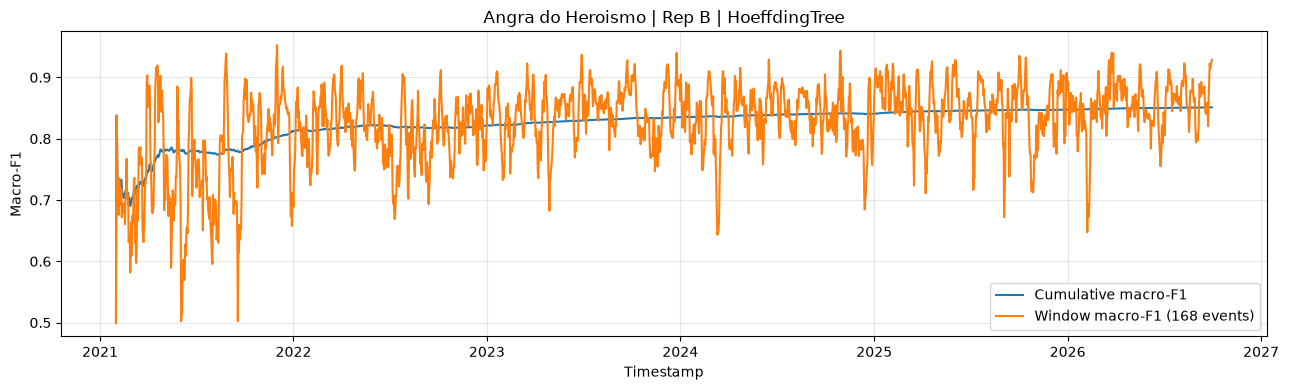

In [8]:
plot_history = history.iloc[::24]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(plot_history['timestamp'], plot_history['cumulative_macro_f1'], label='Cumulative macro-F1')
ax.plot(plot_history['timestamp'], plot_history['window_macro_f1'], label=f'Window macro-F1 ({window_size} events)')
ax.set_title(f"{s['city']} | Rep B | HoeffdingTree")
ax.set_xlabel('Timestamp')
ax.set_ylabel('Macro-F1')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# <font color='#BFD72F' size=6>**4. Full Experiment**</font> <a class="anchor" id="4"></a>

[Back to TOC](#toc)

**Runtime warning:** the following is the same cities × representations × models loop as the terminal command and may take **several minutes**; **ARF is the slowest** learner. Keep `RUN_FULL_EXPERIMENT = True` to reproduce the experiment. Set it to `False` to skip training and load existing audit outputs from the configured results directory. Before the full loop, reset both seeds so the demonstration runs do not change the full experiment’s random state.

In [9]:
RUN_FULL_EXPERIMENT = True

## <font color='#BFD72F' size=5>4.1 Run All Cities × Representations × Models</font> <a class="anchor" id="4_1"></a>

[Back to TOC](#toc)

In [10]:
if RUN_FULL_EXPERIMENT:
    random.seed(seed)
    np.random.seed(seed)
    rows = []
    histories = []
    for key, s in streams.items():
        city = s['city']
        df = s['df']
        y = s['y']
        reps = s['reps']
        valid = s['valid']
        is_warm = s['is_warm']
        for rep_name, X in reps.items():
            learners = [(n, m, True, 'mandatory') for n, m in build_models(seed).items()]
            if include_baselines:
                learners += [
                    (n, m, online, 'baseline')
                    for n, (m, online) in build_baselines(seed).items()
                ]
            for model_name, model, online, role in learners:
                res, run_history = run_prequential(
                    model, X[valid], y[valid].astype(int), is_warm[valid],
                    online=online, window_size=window_size,
                    timestamps=df.loc[valid, 'time'].tolist(), track_memory=track_memory,
                )
                rows.append({
                    'city': city, 'representation': rep_name, 'model': model_name,
                    'role': role, **res, **model_complexity(model),
                })
                histories.append(run_history.assign(
                    city=city, representation=rep_name, model=model_name, role=role,
                ))
                print(
                    f"{city} | Rep {rep_name} | {model_name}: "
                    f"MacroF1={res['macro_f1']:.4f} Recall={res['recall']:.4f}"
                )
    metrics_df = pd.DataFrame(rows)
    history_df = pd.concat(histories, ignore_index=True)
else:
    print('Full experiment skipped; existing audit files will be loaded in section 4.2.')

Angra do Heroismo | Rep A | GaussianNB: MacroF1=0.7559 Recall=0.5098
Angra do Heroismo | Rep A | OnlineLogReg: MacroF1=0.8173 Recall=0.6998
Angra do Heroismo | Rep A | HoeffdingTree: MacroF1=0.8628 Recall=0.8257
Angra do Heroismo | Rep A | OnlineBagging: MacroF1=0.8683 Recall=0.8373
Angra do Heroismo | Rep A | ARF: MacroF1=0.8617 Recall=0.8223
Angra do Heroismo | Rep A | Majority: MacroF1=0.4188 Recall=0.0562
Angra do Heroismo | Rep A | Persistence: MacroF1=0.8707 Recall=0.8456
Angra do Heroismo | Rep A | FrozenLogReg: MacroF1=0.7255 Recall=0.5417
Angra do Heroismo | Rep B | GaussianNB: MacroF1=0.7653 Recall=0.6051
Angra do Heroismo | Rep B | OnlineLogReg: MacroF1=0.8410 Recall=0.7726
Angra do Heroismo | Rep B | HoeffdingTree: MacroF1=0.8512 Recall=0.8039
Angra do Heroismo | Rep B | OnlineBagging: MacroF1=0.8592 Recall=0.8177
Angra do Heroismo | Rep B | ARF: MacroF1=0.8527 Recall=0.8161
Angra do Heroismo | Rep B | Majority: MacroF1=0.4188 Recall=0.0562
Angra do Heroismo | Rep B | Persi

## <font color='#BFD72F' size=5>4.2 Save Audit Outputs</font> <a class="anchor" id="4_2"></a>

[Back to TOC](#toc)

In [11]:
if RUN_FULL_EXPERIMENT:
    out.mkdir(parents=True, exist_ok=True)
    metrics_df.to_csv(out / 'metrics.csv', index=False)
    history_df.to_csv(out / 'history.csv.gz', index=False, compression='gzip')
    config_rows = {
        'assignment_code': cfg['assignment']['code'],
        'target': target,
        'city_a': cfg['cities']['city_a']['name'],
        'city_b': cfg['cities']['city_b']['name'],
        'start_date': period['start_date'],
        'end_date': period['end_date'],
        'warmup_hours': warm_n,
        'seed': seed,
        'thresholds': thresholds,
        'window_size': window_size,
        'features_windows': cfg['features']['windows'],
        'race_window': cfg['analysis']['race_window'],
        'platform': platform.platform(),
        'track_memory': track_memory,
        'include_baselines': include_baselines,
        'python': platform.python_version(),
        'river': river.__version__,
        'scikit-learn': sklearn.__version__,
        'matplotlib': matplotlib.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__,
        **{f'model_{k}': str(v._get_params()) for k, v in build_models(seed).items()},
        **{
            f'baseline_{k}': f'{v._get_params()}; online={online}'
            for k, (v, online) in build_baselines(seed).items()
        },
    }
    pd.Series(config_rows).to_csv(out / 'configurations.csv', header=['value'])
    print(f'Audit outputs saved to {out}')
else:
    for filename in ('metrics.csv', 'history.csv.gz', 'configurations.csv'):
        if not (out / filename).exists():
            raise FileNotFoundError(f'Missing {out / filename}; run the full experiment first.')
    metrics_df = pd.read_csv(out / 'metrics.csv')
    history_df = pd.read_csv(out / 'history.csv.gz', parse_dates=['timestamp'])
    print(f'Existing audit outputs loaded from {out}; no files overwritten.')

Audit outputs saved to D:\OneDrive - NOVAIMS\S1\Data Stream Mining\Projects\Assignment 1\real-time-weather-data\results


## <font color='#BFD72F' size=5>4.3 Quick Look</font> <a class="anchor" id="4_3"></a>

[Back to TOC](#toc)

In [12]:
display(metrics_df[[
    'city', 'representation', 'model', 'role', 'macro_f1', 'recall',
    'pred_ms_per_event', 'update_ms_per_event',
]])

,city,representation,model,role,macro_f1,recall,pred_ms_per_event,update_ms_per_event
0,Angra do Heroismo,A,GaussianNB,mandatory,0.755916,0.509790,0.173617,0.007866
1,Angra do Heroismo,A,OnlineLogReg,mandatory,0.817287,0.699750,0.005189,0.012638
2,Angra do Heroismo,A,HoeffdingTree,mandatory,0.862840,0.825674,0.012327,0.034864
3,Angra do Heroismo,A,OnlineBagging,mandatory,0.868250,0.837313,0.119822,0.319508
4,Angra do Heroismo,A,ARF,mandatory,0.861748,0.822278,0.174564,1.139371
5,Angra do Heroismo,A,Majority,baseline,0.418775,0.056244,0.001559,0.001148
6,Angra do Heroismo,A,Persistence,baseline,0.870653,0.845604,0.000235,0.000220
7,Angra do Heroismo,A,FrozenLogReg,baseline,0.725452,0.541708,0.007141,0.000000
8,Angra do Heroismo,B,GaussianNB,mandatory,0.765309,0.605095,0.195695,0.015991
9,Angra do Heroismo,B,OnlineLogReg,mandatory,0.841012,0.772627,0.012710,0.037974
